# Pod 8: the exoplanet catalog

A **table** is an array with named columns. Today's library, `pandas`, reads a table from a text file in one line and gives you five moves: the shape, a column, a row, a filter, a sort. Everything you know from arrays carries over: a column is an array, a filter is a mask.

Run the first cell; it must print a path containing `astr119`.

**How to work the "your code here" cells.** Each one asks for a few lines. Write one sentence of what you expect in a text cell first, then either type it yourself or ask Claude for *that cell only* (paste the comment lines as your request), read what comes back, run it, compare with your sentence. That is the Protocol, and it is how you will use Claude in the project.

In [2]:
import sys
print(sys.executable)   # must contain 'astr119'

C:\Users\abrah\miniconda3\envs\astr119\python.exe


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Part 1: the five moves, together

These cells are the type-along. Run each one with the room, read what comes back.

In [4]:
# T1  A dictionary is a table with named columns; pandas turns it into a DataFrame.
cities = {
    "name": ["San Francisco", "New York", "Santa Cruz", "Los Angeles"],
    "summer_temp_F": [55, 85, 70, 90],
    "population_millions": [0.8, 8.3, 0.06, 3.9],
}
df = pd.DataFrame(cities)
df                      # the last line of a cell is shown: a table with a row number down the left

,name,summer_temp_F,population_millions
0,San Francisco,55,0.80
1,New York,85,8.30
2,Santa Cruz,70,0.06
3,Los Angeles,90,3.90


In [5]:
# Try it (T1): a dictionary grows by assignment. Add a key, then a computed one.
cities["baseball_team"] = ["Giants", "Yankees", "Banana Slugs", "Dodgers"]
cities["summer_temp_2050"] = np.array(cities["summer_temp_F"]) + 1.4     # arrays add elementwise; a plain list would not
# Your code here: add "population_2050" with every population grown by 20 percent, then rebuild df = pd.DataFrame(cities) and show it.


In [6]:
# T2  A real table from a text file: sixteen hot Jupiters. The notebook runs in module-4/, so the path starts at data/.
small = pd.read_csv("data/exoplanets_small.csv")
print(small.shape)      # (rows, columns)
print(small.columns)    # the names
small                   # look at it

(16, 6)
Index(['Name', 'Msini', 'semi-major axis', 'orbital period', 'omega',
       'reference'],
      dtype='str')


,Name,Msini,semi-major axis,orbital period,omega,reference
0,WASP-103 b,1.485,0.01987,0.925542,90.0,Gillon 2014
1,WASP-19 b,1.114,0.01632,0.788840,3.0,Hellier 2011
2,WASP-18 b,10.060,0.02014,0.941453,267.9,Triaud 2010
3,HATS-15 b,2.160,0.02714,1.747488,90.0,Ciceri 2016
4,KELT-14 b,1.257,0.03007,1.710057,90.0,Turner 2016
5,HATS-18 b,1.976,0.01762,0.837843,90.0,Penev 2016
6,Kepler-17 b,2.480,0.02679,1.485711,90.0,Desert 2011
7,WASP-46 b,2.085,0.02449,1.430370,90.0,Anderson 2012
8,HAT-P-53 b,1.484,0.03160,1.961624,90.0,Hartman 2015
9,TrES-3 b,1.873,0.02272,1.306190,90.0,Sozzetti 2009


In [7]:
# T3  A column is an array with a name; a row is picked by number with iloc.
print(small["Msini"])           # one column, with its row numbers
print(small["Msini"].values)    # the bare numpy array inside it
print(small.iloc[0])            # row 0: one planet, all its columns
small.iloc[0:3]                 # rows 0, 1, 2: a smaller table

0      1.485
1      1.114
2     10.060
3      2.160
4      1.257
5      1.976
6      2.480
7      2.085
8      1.484
9      1.873
10     2.450
11     1.760
12     3.480
13     1.759
14     2.483
15     1.264
Name: Msini, dtype: float64
[ 1.485  1.114 10.06   2.16   1.257  1.976  2.48   2.085  1.484  1.873
  2.45   1.76   3.48   1.759  2.483  1.264]
Name                WASP-103 b
Msini                    1.485
semi-major axis        0.01987
orbital period        0.925542
omega                     90.0
reference          Gillon 2014
Name: 0, dtype: object


,Name,Msini,semi-major axis,orbital period,omega,reference
0,WASP-103 b,1.485,0.01987,0.925542,90.0,Gillon 2014
1,WASP-19 b,1.114,0.01632,0.788840,3.0,Hellier 2011
2,WASP-18 b,10.060,0.02014,0.941453,267.9,Triaud 2010


In [8]:
# Try it (T3): predict each line before you run it, then uncomment them one at a time.
# small[["Name", "orbital period"]]          # two columns (note the double brackets: a list of names)
# small[["orbital period", "Name"]].iloc[0:5]  # two columns, five rows
# small.iloc[0, 0:3]                          # row 0, the first three columns
# type(small.iloc[0, 0:3])                    # what kind of thing is that? and .values?


In [9]:
# T4  A filter is a mask on a column; sorting is one verb. Predict: how many of the sixteen have Msini below 2?
light = small[small["Msini"] < 2]
print(len(light))
print(small["orbital period"].min())                       # the shortest period, as a number
print(small.sort_values("orbital period").iloc[0]["Name"])  # and whose it is
light.sort_values("Msini")                                 # the light ones, lightest first

9
0.78884
WASP-19 b


,Name,Msini,semi-major axis,orbital period,omega,reference
1,WASP-19 b,1.114,0.01632,0.788840,3.0,Hellier 2011
4,KELT-14 b,1.257,0.03007,1.710057,90.0,Turner 2016
15,WASP-104 b,1.264,0.02919,1.755414,NaN,Smith 2014
8,HAT-P-53 b,1.484,0.03160,1.961624,90.0,Hartman 2015
0,WASP-103 b,1.485,0.01987,0.925542,90.0,Gillon 2014
13,WASP-114 b,1.759,0.02852,1.548774,-70.0,Barros 2016
11,WASP-43 b,1.760,0.01424,0.813475,90.0,Hellier 2011
9,TrES-3 b,1.873,0.02272,1.306190,90.0,Sozzetti 2009
5,HATS-18 b,1.976,0.01762,0.837843,90.0,Penev 2016


In [10]:
# Try it (T4): computations on a column, printed in sentences.
print(f"The longest orbital period is {small['orbital period'].max():.3f} days")
# Your code here: the same sentence for the shortest period, the mean, and the median (look up the median method).


The longest orbital period is 1.962 days


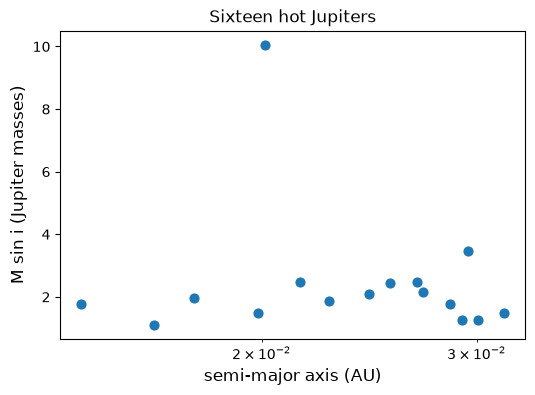

In [11]:
# T5  One figure from a table: mass against distance from the star. Columns go straight into scatter.
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(small["semi-major axis"], small["Msini"], marker="o", s=40)
ax.set_xscale("log")
ax.set_xlabel("semi-major axis (AU)", fontsize=12)
ax.set_ylabel("M sin i (Jupiter masses)", fontsize=12)
ax.set_title("Sixteen hot Jupiters", fontsize=12)
fig.savefig("hot_jupiters_small.png")

## Task 1: the whole catalog

The file `data/exoplanet_eu_catalog_2024-02.csv` is the exoplanet.eu catalog as of February 2024: every confirmed planet, one row each, about a hundred columns. Before each cell, write the prediction on the sheet; then run; then compare.

In [12]:
# 1.1  Read it. Predict: how many planets (rows), how many columns?
cat = pd.read_csv("data/exoplanet_eu_catalog_2024-02.csv", low_memory=False)
print(cat.shape)
cat.head()              # the first five rows; scroll right: the columns go on and on


(5633, 98)


,name,planet_status,mass,mass_error_min,mass_error_max,mass_sini,mass_sini_error_min,mass_sini_error_max,radius,radius_error_min,...,star_sp_type,star_age,star_age_error_min,star_age_error_max,star_teff,star_teff_error_min,star_teff_error_max,star_detected_disc,star_magnetic_field,star_alternate_names
0,11 Com b,Confirmed,16.1284,1.53491,1.53491,16.1284,1.53491,1.53491,NaN,NaN,...,G8 III,NaN,NaN,NaN,4742.0,100.0,100.0,NaN,NaN,NaN
1,11 Oph b,Confirmed,21.0000,3.00000,3.00000,NaN,NaN,NaN,NaN,NaN,...,M9,0.011,0.002,0.002,2375.0,175.0,175.0,NaN,NaN,"Oph 1622-2405, Oph 11A"
2,11 UMi b,Confirmed,11.0873,1.10000,1.10000,11.0873,1.10000,1.10000,NaN,NaN,...,K4III,1.560,0.540,0.540,4340.0,70.0,70.0,NaN,NaN,NaN
3,14 And b,Confirmed,4.6840,0.23000,0.23000,4.6840,0.23000,0.23000,NaN,NaN,...,K0III,NaN,NaN,NaN,4813.0,20.0,20.0,NaN,NaN,NaN
4,14 Her b,Confirmed,NaN,NaN,NaN,NaN,4.95000,4.95000,NaN,NaN,...,K0 V,5.100,NaN,NaN,5311.0,87.0,87.0,NaN,NaN,NaN


In [13]:
# 1.2  Which columns hold a mass? Predict how many column names contain the word "mass".
mass_columns = [c for c in cat.columns if "mass" in c]
print(len(mass_columns))
print(mass_columns)
# Which one would you plot? (mass is the planet's mass in Jupiter masses; mass_sini is the lower limit from radial velocities; star_mass is the star's.)
# Your code here: the same search for the word "radius". How many? Which one is the planet's radius?
radius_columns = [c for c in cat.columns if "radius" in c]
print(len(radius_columns))
print(radius_columns)

10
['mass', 'mass_error_min', 'mass_error_max', 'mass_sini', 'mass_sini_error_min', 'mass_sini_error_max', 'mass_detection_type', 'star_mass', 'star_mass_error_min', 'star_mass_error_max']
7
['radius', 'radius_error_min', 'radius_error_max', 'radius_detection_type', 'star_radius', 'star_radius_error_min', 'star_radius_error_max']


In [27]:
# 1.3  Real tables have holes. Predict: of the planets, how many have BOTH a mass and a semi-major axis measured?
has_both = cat["mass"].notna() & cat["semi_major_axis"].notna()   # notna(): True where there is a value, False where the cell is empty (NaN)
print(has_both.sum())
planets = cat[has_both]                                              # the rows we can plot
# Your code here: how many planets have a mass but NO radius? (notna() on one column, isna() on the other, & between them)
has_one = cat["mass"].notna() & cat["radius"].isna()
print(has_one.sum())
has_large_error = cat["mass_error_max"] > 100 or cat["mass_error_min"] > 100
print(has_large_error.sum())

2705
1565


ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

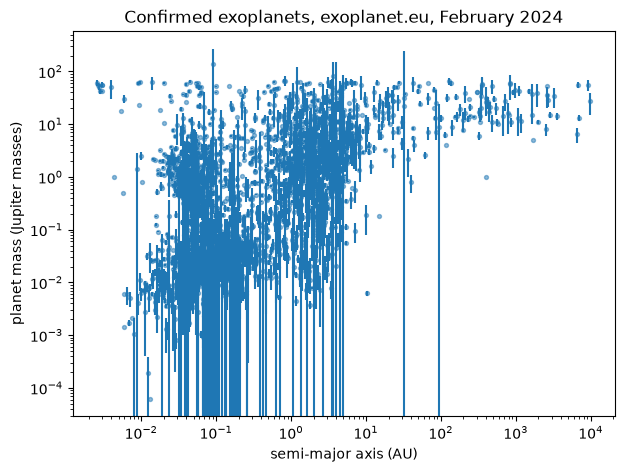

In [29]:
# 1.4  The figure: planet mass against distance from the star, for the planets that have both. Predict the shape of the cloud.
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(planets["semi_major_axis"], planets["mass"], s=8, alpha=0.5)
error = [planets["mass_error_min"], planets["mass_error_max"]]
ax.errorbar(planets["semi_major_axis"], planets["mass"], yerr = error, fmt = 'none')
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("semi-major axis (AU)")
ax.set_ylabel("planet mass (Jupiter masses)")
ax.set_title("Confirmed exoplanets, exoplanet.eu, February 2024")
fig.savefig("exoplanets_mass_vs_a.png")
# Bonus: error bars. The catalog has mass_error_min and mass_error_max; look up ax.errorbar and add them to the figure.


## Task 2: make it yours

Pick one as a pod, or combine, or invent something; each of you in your own notebook. Predict before each run; write what you did on the sheet.

- **How wide is it?** A histogram of `np.log10(planets["mass"])`. Is it one bell curve? Measure its width the three ways from Pod 7 and say which one you trust.
- **Discoveries per year.** `cat["discovered"].value_counts().sort_index()` and a bar chart (`ax.bar`). Which year won, and why might 2024 look small?
- **Hot Jupiters.** Planets with `orbital_period` below 3 days and `mass` above 0.5: how many, and the five heaviest, sorted (`sort_values("mass", ascending=False)`).
- **How were they found?** `cat["detection_type"].value_counts()`; then the 1.4 figure colored by detection type (one `scatter` call per type, with `label=` and a legend). Where do the transit planets sit, and where the radial-velocity ones?
- **Style it.** Markers, sizes, `fontsize`, a figure that still reads in black and white, with colors a color-blind reader can tell apart.
- **Quick look.** pandas can plot by itself: `planets["mass"].plot(kind="hist", bins=50)` (and `logx=True` or `np.log10` first). One line; compare with the matplotlib version.
- **The light ones.** Keep the planets with mass below 2 Jupiter masses, sort them lightest first, and print the ten lightest with their names, masses and periods.
- **Publication-ready.** Take the Task 1 figure and finish it: error bars from `mass_error_min` and `mass_error_max`, a title that states the claim, fonts you can read from the back of the room, saved at `dpi=200`.
- **A combination, or something else** that reads a column, filters it, and shows a figure.

In [ ]:
# Task 2: your code here


Before you upload: **Restart** and **Run All**, check it runs top to bottom. Then upload this notebook, with its outputs, and the photo of the sheet.